# 🧠 Active Learning Strategies Tutorial (modAL-free)

**Full Tutorial Version** — Colab-ready

**Includes:** Least Confidence, Margin Sampling, Entropy, Query-by-Committee (QBC), Query-by-Disagreement (QBD), Expected Error Reduction (simplified), Diversity Sampling.

**Instructions:** Upload this notebook to Google Colab and run cells in order. All code uses only `numpy` + `scikit-learn` + `matplotlib`. No `modAL` dependency.

Date: 2025-10-16


## 0. Setup (install dependencies)

Run the cell below if you're in Google Colab to install required packages.

In [ ]:
!pip install --quiet scikit-learn matplotlib

## 1. Imports and utilities

Run the imports and global configuration cell.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification, load_digits
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.base import clone
import warnings
warnings.filterwarnings('ignore')

print('Libraries loaded. numpy v', np.__version__)

Libraries loaded. numpy v 2.0.2


## 2. Uncertainty-based strategies

This section defines:
- Least Confidence
- Margin Sampling
- Entropy Sampling

Each function returns an `(order, scores)` pair where `order` sorts examples by decreasing uncertainty (most uncertain first).

In [ ]:
def least_confidence(model, X):
    """Least Confidence: 1 - max_class_probability"""
    proba = model.predict_proba(X)
    uncertainty = 1 - np.max(proba, axis=1)
    order = np.argsort(-uncertainty)
    return order, uncertainty

def margin_sampling(model, X):
    """Margin Sampling: 1 - (p1 - p2) where p1 and p2 are top two probs."""
    proba = model.predict_proba(X)
    sorted_probs = -np.sort(-proba, axis=1)
    if sorted_probs.shape[1] > 1:
        margin = sorted_probs[:,0] - sorted_probs[:,1]
    else:
        margin = sorted_probs[:,0]
    uncertainty = 1 - margin
    order = np.argsort(-uncertainty)
    return order, uncertainty

def entropy_sampling(model, X):
    """Entropy Sampling: Shannon entropy of predictive distribution"""
    proba = model.predict_proba(X)
    eps = 1e-12
    ent = -np.sum(proba * np.log(proba + eps), axis=1)
    order = np.argsort(-ent)
    return order, ent

print('Uncertainty strategy functions defined.')

Uncertainty strategy functions defined.


## 3. Committee-based strategies

Defines Query-by-Committee (vote entropy) and Query-by-Disagreement (fraction disagreeing with majority).

In [ ]:
def query_by_committee(committee, X):
    """Vote entropy across committee predictions."""
    votes = np.vstack([clf.predict(X) for clf in committee])
    n_samples = votes.shape[1]
    vote_entropy = np.zeros(n_samples)
    for i in range(n_samples):
        counts = np.bincount(votes[:, i])
        probs = counts / len(committee)
        vote_entropy[i] = -np.sum(probs * np.log(probs + 1e-12))
    order = np.argsort(-vote_entropy)
    return order, vote_entropy

def query_by_disagreement(committee, X):
    """Fraction of committee members that disagree with majority vote."""
    votes = np.vstack([clf.predict(X) for clf in committee])
    n_samples = votes.shape[1]
    disagreement = np.zeros(n_samples)
    for i in range(n_samples):
        counts = np.bincount(votes[:, i])
        majority = np.argmax(counts)
        disagreement[i] = np.mean(votes[:, i] != majority)
    order = np.argsort(-disagreement)
    return order, disagreement

print('Committee strategy functions defined.')

Committee strategy functions defined.


## 4. Diversity & Expected Error Reduction (EER)

Diversity selects samples far from the labeled set. EER here is a **simplified proxy** using entropy (full EER is expensive).

In [ ]:
from sklearn.cluster import KMeans

def diversity_sampling(model, X_pool, X_labeled):
    """Pick points farthest (Euclidean) from the labeled set."""
    X_pool = np.asarray(X_pool)
    X_labeled = np.asarray(X_labeled)
    if X_labeled.size == 0:
        distances = np.ones(len(X_pool))
    else:
        dists = np.linalg.norm(X_pool[:, None, :] - X_labeled[None, :, :], axis=2)
        distances = np.min(dists, axis=1)
    order = np.argsort(-distances)
    return order, distances

def expected_error_reduction(model, X_pool):
    """Simplified EER: use predictive entropy as cheap proxy for expected improvement."""
    return entropy_sampling(model, X_pool)

print('Diversity and simplified EER defined.')

Diversity and simplified EER defined.


## 5. Minimal `ActiveLearner` wrapper

This class mimics modAL's interface (`query`, `teach`, `score`). It retrains the estimator on every `teach` call (suitable for small demos).

In [ ]:
class ActiveLearner:
    def __init__(self, estimator, query_strategy, X_training, y_training):
        self.estimator = estimator
        self.query_strategy = query_strategy
        self.X_training = X_training.copy()
        self.y_training = y_training.copy()
        self.estimator.fit(self.X_training, self.y_training)

    def query(self, X_pool, *args):
        # query_strategy signature can accept (model, X_pool, *extra_args)
        order, scores = self.query_strategy(self.estimator, X_pool, *args)
        qidx = order[0]
        return qidx, X_pool[qidx].reshape(1, -1)

    def teach(self, X_new, y_new):
        X_new = np.asarray(X_new)
        y_new = np.asarray(y_new)
        self.X_training = np.vstack([self.X_training, X_new])
        self.y_training = np.concatenate([self.y_training, y_new])
        self.estimator.fit(self.X_training, self.y_training)

    def score(self, X_test, y_test):
        return accuracy_score(y_test, self.estimator.predict(X_test))

print('ActiveLearner wrapper ready.')

ActiveLearner wrapper ready.


## 6. Helper: run experiments

`run_experiment` runs a pool-based AL loop and plots accuracy vs queries.

In [ ]:
def run_experiment(query_strategy, name='Strategy', n_queries=25, dataset=None, multiclass=False, random_state=42):
    if dataset is None:
        X, y = make_classification(n_samples=800, n_features=10, n_informative=6, random_state=random_state, n_classes=3 if multiclass else 2)
    else:
        X, y = dataset
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=random_state)
    init_idx = np.random.choice(range(len(X_train)), 20, replace=False)
    X_init, y_init = X_train[init_idx], y_train[init_idx]
    X_pool = np.delete(X_train, init_idx, axis=0)
    y_pool = np.delete(y_train, init_idx, axis=0)

    learner = ActiveLearner(LogisticRegression(max_iter=1000), query_strategy, X_init, y_init)
    accs = [learner.score(X_test, y_test)]

    for _ in range(n_queries):
        try:
            qidx, xq = learner.query(X_pool, learner.X_training)
        except TypeError:
            # strategy may expect model and X_pool only
            qidx, xq = learner.query(X_pool)
        yq = np.array([y_pool[qidx]])
        learner.teach(xq, yq)
        X_pool = np.delete(X_pool, qidx, axis=0)
        y_pool = np.delete(y_pool, qidx, axis=0)
        accs.append(learner.score(X_test, y_test))

    plt.figure(figsize=(7,4))
    plt.plot(accs, marker='o')
    plt.title(name)
    plt.xlabel('Queries')
    plt.ylabel('Accuracy')
    plt.grid(True)
    plt.show()
    print(f'Final accuracy ({name}):', round(accs[-1], 4))
    return accs

## 7. Demos — run all strategies sequentially

This cell runs each strategy and shows plots.

Running uncertainty-based strategies...


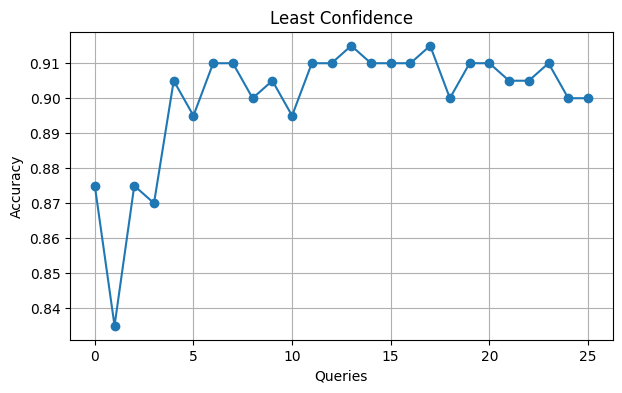

Final accuracy (Least Confidence): 0.9


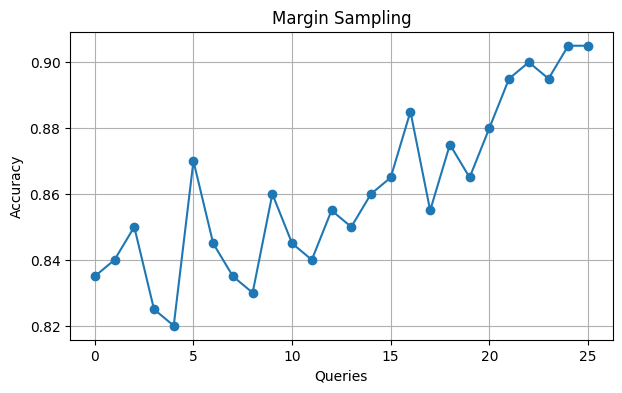

Final accuracy (Margin Sampling): 0.905


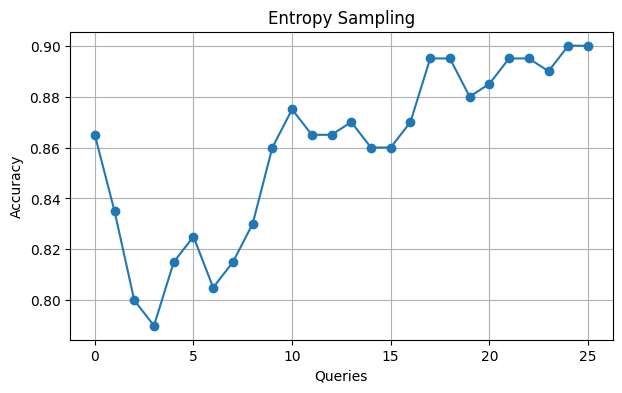

Final accuracy (Entropy Sampling): 0.9

Running diversity sampling...


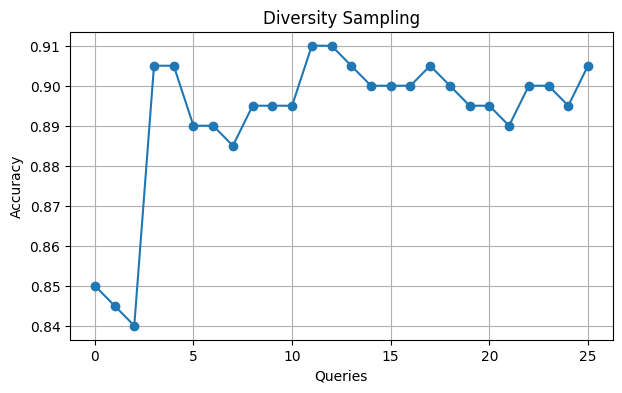

Final accuracy (Diversity Sampling): 0.905

Running simplified EER (entropy proxy)...


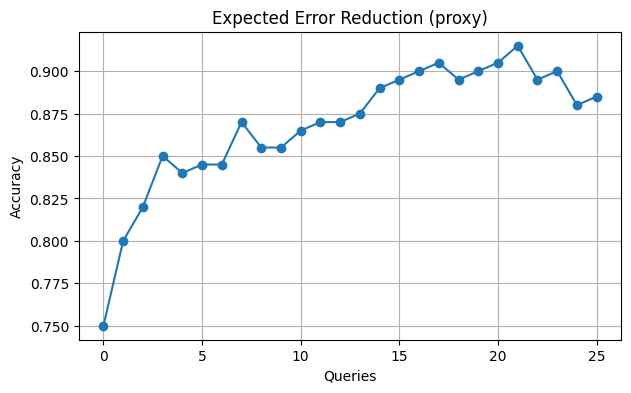

Final accuracy (Expected Error Reduction (proxy)): 0.885

Running Query-by-Committee (QBC) demo (multiclass example)...


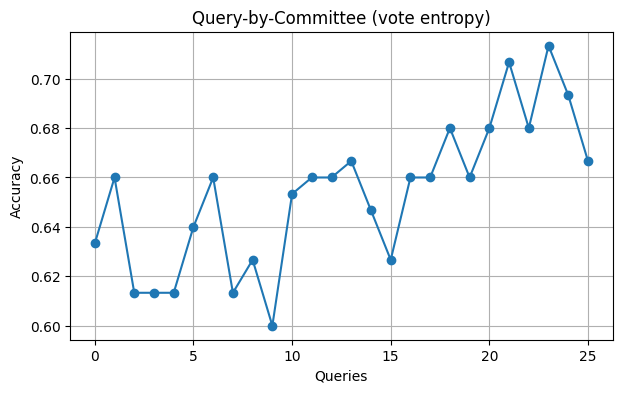

Final QBC accuracy: 0.6666666666666666


In [ ]:
# Prepare a dataset (binary classification by default)
X, y = make_classification(n_samples=800, n_features=12, n_informative=8, random_state=0)

print('Running uncertainty-based strategies...')
run_experiment(least_confidence, 'Least Confidence', n_queries=25, dataset=(X,y))
run_experiment(margin_sampling, 'Margin Sampling', n_queries=25, dataset=(X,y))
run_experiment(entropy_sampling, 'Entropy Sampling', n_queries=25, dataset=(X,y))

print('\nRunning diversity sampling...')
run_experiment(lambda model, X_pool, X_lab: diversity_sampling(model, X_pool, X_lab),
               'Diversity Sampling', n_queries=25, dataset=(X,y))

print('\nRunning simplified EER (entropy proxy)...')
run_experiment(expected_error_reduction, 'Expected Error Reduction (proxy)', n_queries=25, dataset=(X,y))

print('\nRunning Query-by-Committee (QBC) demo (multiclass example)...')
# QBC uses its own loop because committee members are separate models
Xc, yc = make_classification(n_samples=600, n_features=8, n_informative=6, n_classes=3, random_state=1)
X_train, X_test, y_train, y_test = train_test_split(Xc, yc, test_size=0.25, random_state=1)
init_idx = np.random.choice(range(len(X_train)), 30, replace=False)
X_init, y_init = X_train[init_idx], y_train[init_idx]
X_pool = np.delete(X_train, init_idx, axis=0)
y_pool = np.delete(y_train, init_idx, axis=0)

committee = [
    RandomForestClassifier(n_estimators=30, random_state=0).fit(X_init, y_init),
    RandomForestClassifier(n_estimators=30, random_state=1).fit(X_init, y_init),
    LogisticRegression(max_iter=1000, random_state=2).fit(X_init, y_init)
]
accs = [accuracy_score(y_test, committee[0].predict(X_test))]
n_queries = 25
for i in range(n_queries):
    order, _ = query_by_committee(committee, X_pool)
    qidx = order[0]
    xq, yq = X_pool[qidx].reshape(1,-1), np.array([y_pool[qidx]])
    X_init = np.vstack([X_init, xq])
    y_init = np.concatenate([y_init, yq])
    for k, clf in enumerate(committee):
        committee[k] = clone(clf)
        committee[k].fit(X_init, y_init)
    X_pool = np.delete(X_pool, qidx, axis=0)
    y_pool = np.delete(y_pool, qidx, axis=0)
    accs.append(accuracy_score(y_test, committee[0].predict(X_test)))

plt.figure(figsize=(7,4))
plt.plot(accs, marker='o')
plt.title('Query-by-Committee (vote entropy)')
plt.xlabel('Queries')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show()
print('Final QBC accuracy:', accs[-1])

---

## Notes & next steps

- The notebook uses simple retraining on each newly labeled sample; for large data use `partial_fit` or minibatch updates.
- **Expected Error Reduction** here is a proxy (entropy). Implementing true EER requires hypothetically labeling, retraining and estimating validation loss per label — expensive but possible for tiny pools.
- For deep models, consider uncertainty methods like MC-Dropout or ensemble variance.



